In [1]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import pandas as pd


from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D, BatchNormalization, InputLayer, Reshape
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2

import warnings
warnings.filterwarnings('ignore')


In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kritikseth/fruit-and-vegetable-image-recognition")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fruit-and-vegetable-image-recognition' dataset.
Path to dataset files: /kaggle/input/fruit-and-vegetable-image-recognition


In [4]:
import os

print(os.listdir(path))

['validation', 'test', 'train']


In [5]:
train_path = os.path.join(path, "train")

print(os.listdir(train_path))

['capsicum', 'sweetcorn', 'orange', 'tomato', 'turnip', 'ginger', 'raddish', 'pomegranate', 'pineapple', 'jalepeno', 'apple', 'carrot', 'lettuce', 'bell pepper', 'eggplant', 'beetroot', 'kiwi', 'pear', 'cabbage', 'cauliflower', 'paprika', 'lemon', 'sweetpotato', 'grapes', 'cucumber', 'corn', 'banana', 'garlic', 'chilli pepper', 'watermelon', 'mango', 'peas', 'onion', 'potato', 'spinach', 'soy beans']


In [7]:
labels = sorted(os.listdir(path + "/train"))

img_path = path + "/train/"

In [8]:
train_path = path + "/train/"
test_path = path + "/test/"
validation_path = path + "/validation/"

labels = sorted(os.listdir(train_path))

In [9]:
img_list = []
label_list = []
data_type = []

for folder in [train_path, test_path]:
    for label in labels:
        for img_file in os.listdir(folder + label):
            img_list.append(folder + label + '/' + img_file)
            label_list.append(label)
            data_type.append("train" if folder == train_path else "test")

In [10]:
df=pd.DataFrame({'img':img_list , 'label':label_list,"data_type": data_type})

In [11]:
df.head()

,img,label,data_type
0,/kaggle/input/fruit-and-vegetable-image-recogn...,apple,train
1,/kaggle/input/fruit-and-vegetable-image-recogn...,apple,train
2,/kaggle/input/fruit-and-vegetable-image-recogn...,apple,train
3,/kaggle/input/fruit-and-vegetable-image-recogn...,apple,train
4,/kaggle/input/fruit-and-vegetable-image-recogn...,apple,train


In [12]:
d = {label: i for i, label in enumerate(labels)} #36 sınıf oldugu için oto oluşturduk

df['encode_label'] = df['label'].map(d)

In [15]:
df[['label', 'encode_label']].head()

,label,encode_label
0,apple,0
1,apple,0
2,apple,0
3,apple,0
4,apple,0


In [16]:
x=[]
for img in df['img']:
    img = cv2.imread(str(img))
    img = cv2.resize(img,(128,128))
    img = (img/255.0).astype(np.float32)
    x.append(img)

In [17]:
x=np.array(x,dtype=np.float32)

In [18]:
y=df['encode_label']

In [19]:
train_df = df[df['data_type'] == 'train']
test_df = df[df['data_type'] == 'test']

x_train = x[train_df.index]
x_test = x[test_df.index]

y_train = y[train_df.index]
y_test = y[test_df.index]

In [20]:
y_train = np.array(y_train, dtype=np.int32)
y_test = np.array(y_test, dtype=np.int32)

In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, Input

model = Sequential([
    Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(256, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),

    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(36, activation='softmax')
])



In [26]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [27]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 36)             │         9,252 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 614,500 (2.34 MB)

 Trainable params: 612,772 (2.34 MB)

 Non-trainable params: 1,728 (6.75 KB)

In [29]:
history_cnn=model.fit(x_train,y_train,validation_data=(x_test,y_test), epochs=20,verbose=1)

Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 40s 274ms/step - accuracy: 0.5522 - loss: 1.4591 - val_accuracy: 0.4875 - val_loss: 1.9515
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5868 - loss: 1.3362 - val_accuracy: 0.5181 - val_loss: 1.8414
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6308 - loss: 1.2201 - val_accuracy: 0.4206 - val_loss: 2.3280
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6417 - loss: 1.1665 - val_accuracy: 0.6017 - val_loss: 1.5210
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6597 - loss: 1.0825 - val_accuracy: 0.7799 - val_loss: 0.7342
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6754 - loss: 0.9860 - val_accuracy: 0.6685 - val_loss: 1.0678
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.6928 - loss: 0.9598 - val_accuracy: 0.6880 - val_loss: 1.0981
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7294 - loss: 0.8563 - val_accuracy: 0.6769 -

In [30]:
model.save('Fruits.model.keras')

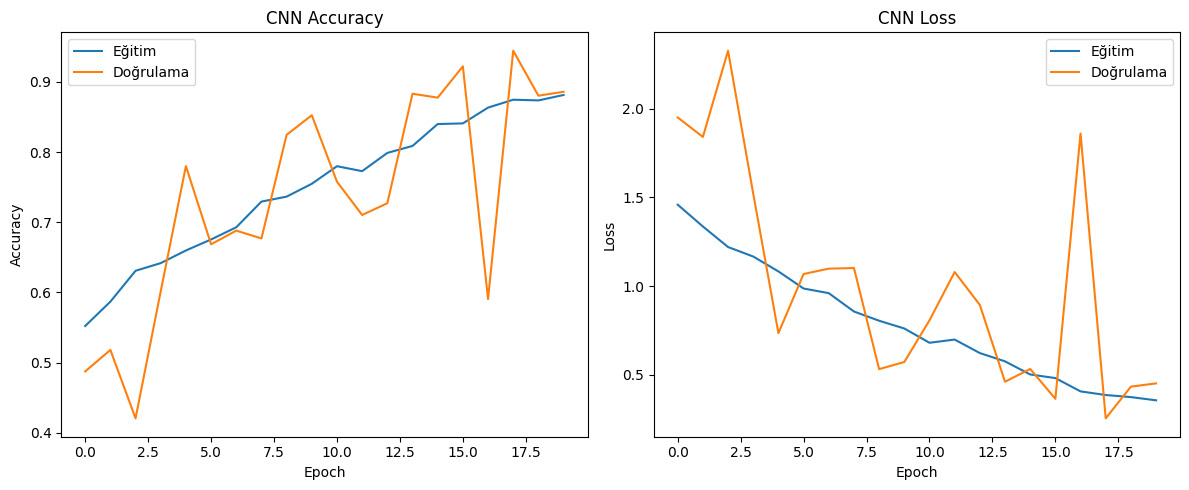

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy grafiği
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Eğitim')
plt.plot(history_cnn.history['val_accuracy'], label='Doğrulama')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss grafiği
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Eğitim')
plt.plot(history_cnn.history['val_loss'], label='Doğrulama')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()

# Grafikleri kaydet
plt.savefig('CNN_Grafikleri.png', dpi=300, bbox_inches='tight')

plt.show()

In [32]:
# Transfer Learning

In [33]:
from tensorflow.keras.applications import VGG16, ResNet50

In [34]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [41]:
data_dir=path
img_width,img_height=128,128
train_datagen=ImageDataGenerator(rescale=1/255, validation_split=.20)

train_datagenerator = train_datagen.flow_from_directory(
    directory=path + "/train",
    target_size=(128, 128),
    class_mode='categorical',
    batch_size=32
)
test_datagen=ImageDataGenerator(rescale=1/255, validation_split=.20)

test_datagenerator = test_datagen.flow_from_directory(
    directory=path + "/test",
    target_size=(128, 128),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

base_model=VGG16(weights='imagenet', input_shape=(img_width,img_height,3), include_top=False)
#base_model=ResNet50(weights='imagenet', input_shape=(img_width,img_height,3), include_top=False) << bunu da deneyebiliridk

model=Sequential()
model.add(base_model)
for layer in base_model.layers:
    layer.trainable=False
model.add(Flatten())
model.add(Dense(1024, activation='relu'))
model.add(Dense(36, activation='softmax'))

model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

Found 3115 images belonging to 36 classes.
Found 359 images belonging to 36 classes.


In [42]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1024)           │     8,389,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 36)             │        36,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,141,220 (88.28 MB)

 Trainable params: 8,426,532 (32.14 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [43]:
history=model.fit(train_datagenerator,epochs=30,validation_data=test_datagenerator)

Epoch 1/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.3332 - loss: 2.7164 - val_accuracy: 0.8162 - val_loss: 0.8081
Epoch 2/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 97s 986ms/step - accuracy: 0.7085 - loss: 1.0489 - val_accuracy: 0.9192 - val_loss: 0.3728
Epoch 3/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 94s 963ms/step - accuracy: 0.8594 - loss: 0.5263 - val_accuracy: 0.9331 - val_loss: 0.3050
Epoch 4/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.9332 - loss: 0.2964 - val_accuracy: 0.9499 - val_loss: 0.2220
Epoch 5/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.9624 - loss: 0.1679 - val_accuracy: 0.9582 - val_loss: 0.1822
Epoch 6/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.9804 - loss: 0.0977 - val_accuracy: 0.9638 - val_loss: 0.1381
Epoch 7/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 96s 973ms/step - accuracy: 0.9875 - loss: 0.0673 - val_accuracy: 0.9666 - val_loss: 0.1753
Epoch 8/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.9862 - loss: 0.0661 - val_accuracy: 0.9582

In [44]:
model.save('Fruits_modelTL.keras')

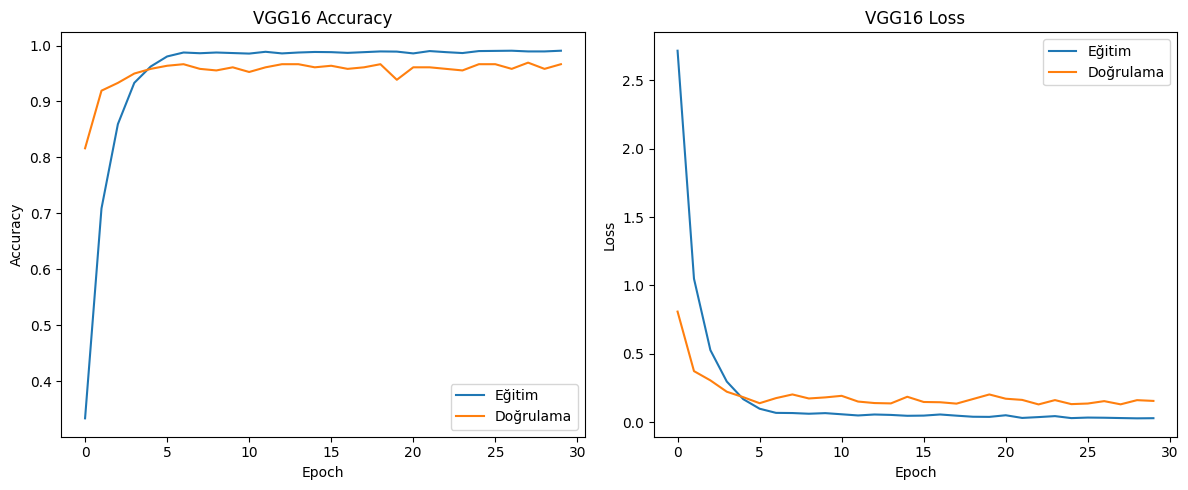

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy grafiği
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Eğitim')
plt.plot(history.history['val_accuracy'], label='Doğrulama')
plt.title('VGG16 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss grafiği
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Eğitim')
plt.plot(history.history['val_loss'], label='Doğrulama')
plt.title('VGG16 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()

# Grafikleri kaydet
plt.savefig('VGG16_Grafikleri.png', dpi=300, bbox_inches='tight')

plt.show()